In [1]:
# ============================================================================
# CELDA 1: IMPORTACIONES Y CONFIGURACIÓN DE RUTAS
# ============================================================================

import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ajustar ruta del proyecto
NOTEBOOK_DIR = os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

# Importar módulos del proyecto
from core.parameters import SystemParameters, OptimizationParameters
from core.data_loader import SystemData
from core.system_cache import SystemCache
from core.power_flow import power_flow_hourly_optimized

# Configuración global de estilo
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 20

# Directorio de salida para figuras iniciales
OUTPUT_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'analisis', 'inicial')
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Módulos importados correctamente")
print(f"Directorio de salida: {OUTPUT_DIR}")

Módulos importados correctamente
Directorio de salida: G:\Mi unidad\TESIS\CODIGO\codigo\proyecto\outputs\analisis\inicial


In [2]:
# ============================================================================
# CELDA 2: CARGA DEL SISTEMA Y CACHE
# ============================================================================

# Elegir sistema
SISTEMA = 'IEEE33'  # o 'IEEE69'

# Parámetros del sistema
sys_params = SystemParameters()
system_data = SystemData(system_type=SISTEMA)
cache = SystemCache(sys_params, system_data)

print(f"Sistema cargado: {system_data.name} ({system_data.nbus} barras, {system_data.nline} líneas)")

# Extraer perfiles horarios y tarifas desde cache
hours = np.arange(24)
pv_factor = cache.pv_factor
demand_factors = cache.demand_factors  # columnas: residencial, comercial, industrial
cost_energy = cache.cost_energy_hourly  # columnas: residencial, industrial, comercial

residential_demand = demand_factors[:, 0]
commercial_demand = demand_factors[:, 1]
industrial_demand = demand_factors[:, 2]

residential_price = cost_energy[:, 0]
industrial_price = cost_energy[:, 1]
commercial_price = cost_energy[:, 2]

Sistema cargado: IEEE33 (33 barras, 32 líneas)


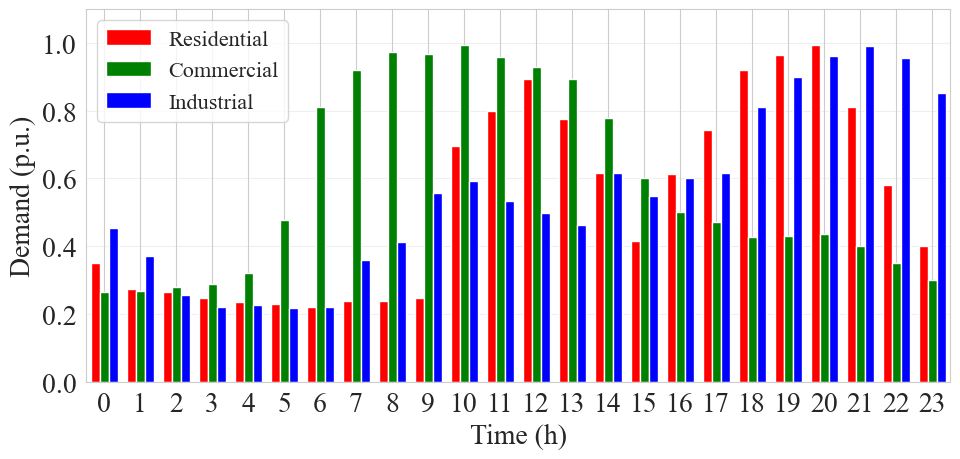

In [3]:
# ============================================================================
# CELDA 3: PERFILES DE DEMANDA (BARRAS AGRUPADAS)
# ============================================================================

fig, ax = plt.subplots(figsize=(10, 5))
bar_width = 0.25
x = hours

ax.bar(x - bar_width, residential_demand, width=bar_width, label='Residential', color='red')
ax.bar(x, commercial_demand, width=bar_width, label='Commercial', color='green')
ax.bar(x + bar_width, industrial_demand, width=bar_width, label='Industrial', color='blue')

ax.set_xlabel('Time (h)', fontsize=20)
ax.set_ylabel('Demand (p.u.)', fontsize=20)
ax.legend(fontsize=16)
ax.grid(True, alpha=0.3, axis='y')
ax.set_xlim(-0.5, 23.5)
ax.set_xticks(range(0, 24, 1))
ax.tick_params(axis='both', labelsize=20)
ax.set_ylim(0, 1.1)
plt.tight_layout()

# Guardar
ruta_demanda = os.path.join(OUTPUT_DIR, 'perfiles_demanda.png')
plt.savefig(ruta_demanda, dpi=600, bbox_inches='tight')
plt.savefig(ruta_demanda.replace('.png', '.svg'), bbox_inches='tight')
plt.show()

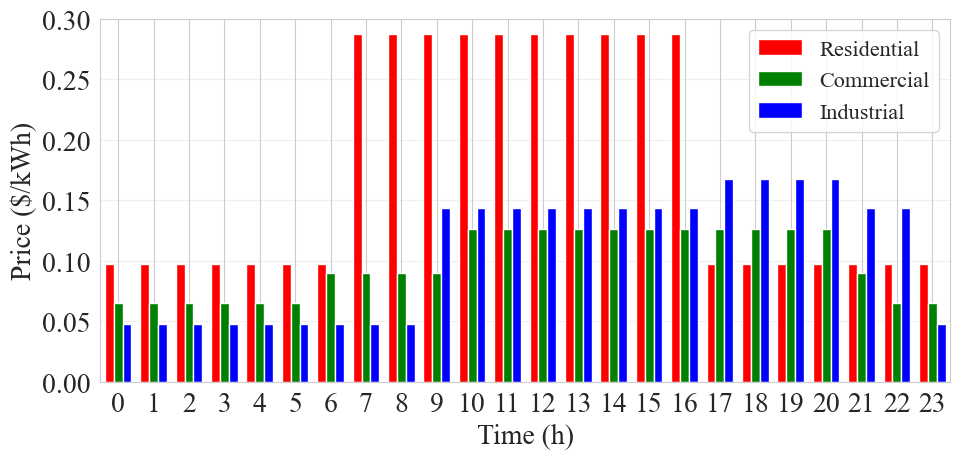

In [4]:
# ============================================================================
# CELDA 4: PRECIOS DE TARIFAS (BARRAS AGRUPADAS)
# ============================================================================

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - bar_width, residential_price, width=bar_width, label='Residential', color='red')
ax.bar(x, commercial_price, width=bar_width, label='Commercial', color='green')
ax.bar(x + bar_width, industrial_price, width=bar_width, label='Industrial', color='blue')

ax.set_xlabel('Time (h)', fontsize=20)
ax.set_ylabel('Price ($/kWh)', fontsize=20)
ax.legend(fontsize=16)
ax.grid(True, alpha=0.3, axis='y')
ax.set_xlim(-0.5, 23.5)
ax.set_xticks(range(0, 24, 1))
ax.tick_params(axis='both', labelsize=20)
ax.set_ylim(0, 0.3)
plt.tight_layout()

ruta_tarifas = os.path.join(OUTPUT_DIR, 'tariff_prices.png')
plt.savefig(ruta_tarifas, dpi=600, bbox_inches='tight')
plt.savefig(ruta_tarifas.replace('.png', '.svg'), bbox_inches='tight')
plt.show()

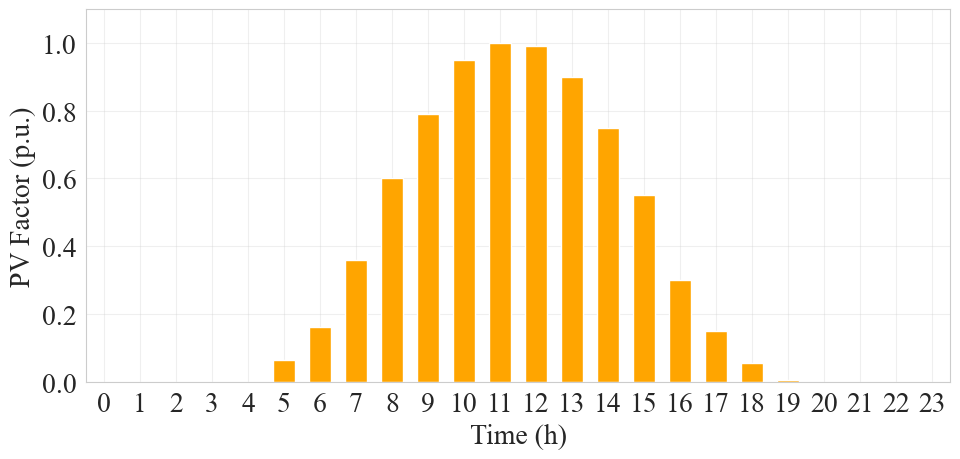

In [5]:
# ============================================================================
# CELDA 5: CURVA DE FACTOR PV
# ============================================================================

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(hours, pv_factor, color='orange', width=0.6)

ax.set_xlabel('Time (h)', fontsize=20)
ax.set_ylabel('PV Factor (p.u.)', fontsize=20)
ax.grid(True, alpha=0.3)
ax.set_xlim(-0.5, 23.5)
ax.set_xticks(range(0, 24, 1))
ax.tick_params(axis='both', labelsize=20)
ax.set_ylim(0, 1.1)
plt.tight_layout()

ruta_pv = os.path.join(OUTPUT_DIR, 'pv_curve.png')
plt.savefig(ruta_pv, dpi=600, bbox_inches='tight')
plt.savefig(ruta_pv.replace('.png', '.svg'), bbox_inches='tight')
plt.show()

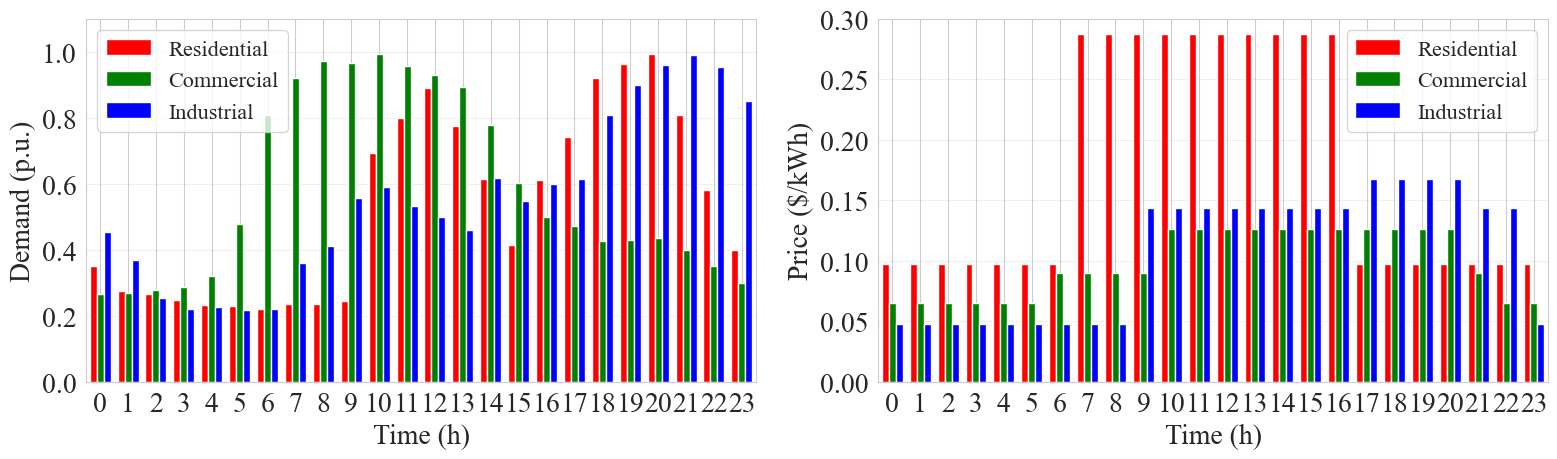

In [7]:
# ============================================================================
# CELDA 6: FIGURA COMBINADA (DEMANDA Y TARIFAS EN DOS PANELES)
# ============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Panel izquierdo: demanda
ax1.bar(x - bar_width, residential_demand, width=bar_width, label='Residential', color='red')
ax1.bar(x, commercial_demand, width=bar_width, label='Commercial', color='green')
ax1.bar(x + bar_width, industrial_demand, width=bar_width, label='Industrial', color='blue')
ax1.set_xlabel('Time (h)', fontsize=20)
ax1.set_ylabel('Demand (p.u.)', fontsize=20)
ax1.legend(fontsize=16)
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_xlim(-0.5, 23.5)
ax1.set_xticks(range(0, 24, 1))
ax1.tick_params(axis='both', labelsize=20)
ax1.set_ylim(0, 1.1)

# Panel derecho: tarifas
ax2.bar(x - bar_width, residential_price, width=bar_width, label='Residential', color='red')
ax2.bar(x, commercial_price, width=bar_width, label='Commercial', color='green')
ax2.bar(x + bar_width, industrial_price, width=bar_width, label='Industrial', color='blue')
ax2.set_xlabel('Time (h)', fontsize=20)
ax2.set_ylabel('Price ($/kWh)', fontsize=20)
ax2.legend(fontsize=16)
ax2.grid(True, alpha=0.3, axis='y')
ax2.set_xlim(-0.5, 23.5)
ax2.set_xticks(range(0, 24, 1))
ax2.tick_params(axis='both', labelsize=20)
ax2.set_ylim(0, 0.3)

plt.tight_layout()
ruta_combinada = os.path.join(OUTPUT_DIR, 'perfiles_demanda_tarifas.png')
# plt.savefig(ruta_combinada, dpi=600, bbox_inches='tight')
# plt.savefig(ruta_combinada.replace('.png', '.svg'), bbox_inches='tight')
plt.show()

Voltaje mínimo base: 0.9163 p.u.
Voltaje máximo base: 1.0000 p.u.


C:\Users\ander\AppData\Local\Temp\ipykernel_81156\1189512419.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


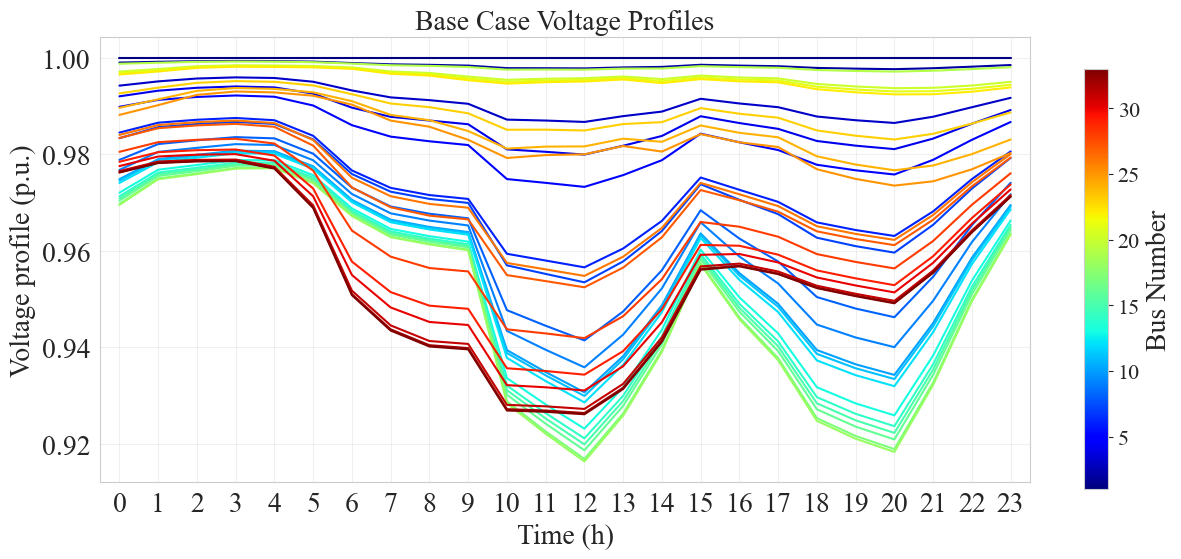

In [9]:
# ============================================================================
# CELDA 7: VOLTAJES BASE (SIN COMPENSACIÓN) PARA TODAS LAS BARRAS
# ============================================================================

# Ejecutar flujos de potencia base para las 24 horas
NC_max = 4  # no se usa en caso base pero necesario para la función
resultados_base = []
for hora in range(24):
    res = power_flow_hourly_optimized(None, hora, np.zeros(NC_max), 0, cache,
                                      with_compensation=False)
    resultados_base.append(res)

# Extraer voltajes mínimos y máximos
Vmin_base = min([min(np.abs(res['Vm'])) for res in resultados_base])
Vmax_base = max([max(np.abs(res['Vm'])) for res in resultados_base])
print(f"Voltaje mínimo base: {Vmin_base:.4f} p.u.")
print(f"Voltaje máximo base: {Vmax_base:.4f} p.u.")

# Graficar perfiles de voltaje (todas las barras, coloreadas)
nbus = system_data.nbus
colores = plt.cm.jet(np.linspace(0, 1, nbus))
horas_plot = np.arange(24)

fig, ax = plt.subplots(figsize=(10, 6))
for i in range(nbus):
    voltajes = [np.abs(resultados_base[h]['Vm'][i]) for h in range(24)]
    ax.plot(horas_plot, voltajes, color=colores[i], linewidth=1.5)

ax.set_xlabel('Time (h)', fontsize=20)
ax.set_ylabel('Voltage profile (p.u.)', fontsize=20)
ax.set_title('Base Case Voltage Profiles', fontsize=20)
ax.set_xlim(-0.5, 23.5)
ax.set_xticks(range(0, 24, 1))
ax.tick_params(axis='both', labelsize=20)
ax.grid(True, alpha=0.3)

# Colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
sm = plt.cm.ScalarMappable(cmap=plt.cm.jet, norm=plt.Normalize(vmin=1, vmax=nbus))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('Bus Number', fontsize=20)
cbar.ax.tick_params(labelsize=16)

plt.tight_layout(rect=[0, 0, 0.9, 1])
ruta_voltajes_base = os.path.join(OUTPUT_DIR, 'voltajes_base.png')
# plt.savefig(ruta_voltajes_base, dpi=600, bbox_inches='tight')
# plt.savefig(ruta_voltajes_base.replace('.png', '.svg'), bbox_inches='tight')
plt.show()

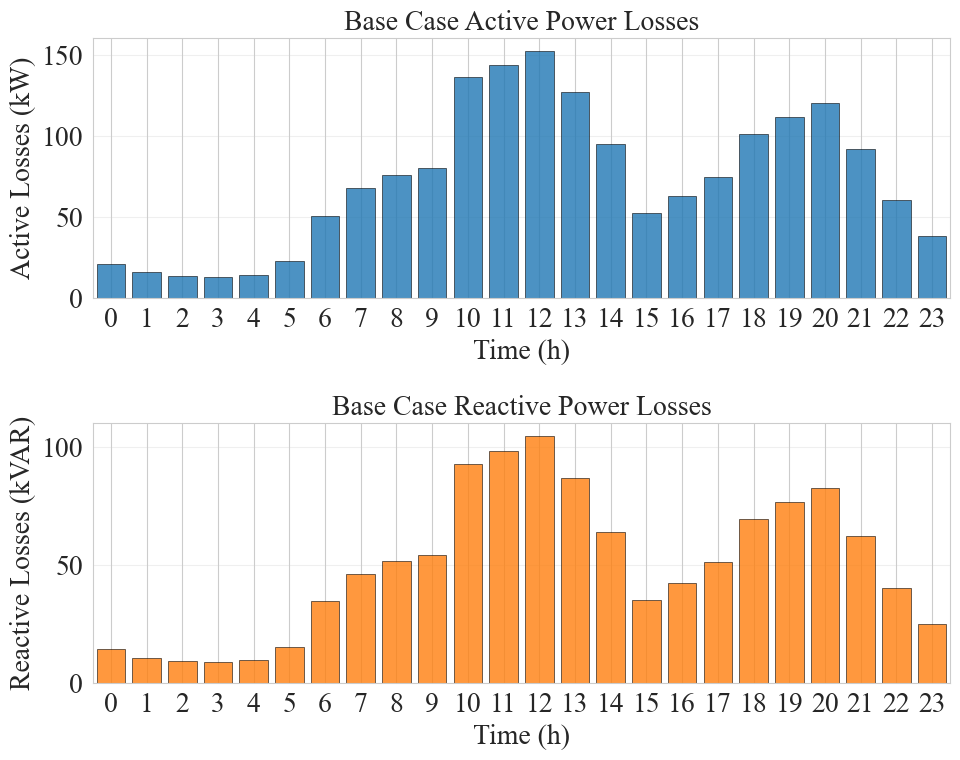

Análisis inicial completado. Figuras guardadas en: G:\Mi unidad\TESIS\CODIGO\codigo\proyecto\outputs\analisis\inicial


In [10]:
# ============================================================================
# CELDA 8: PÉRDIDAS BASE ACTIVAS Y REACTIVAS (TOTALES POR HORA)
# ============================================================================

PTloss_hora = [res['PTloss'] for res in resultados_base]
QTloss_hora = [res['QTloss'] for res in resultados_base]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# Pérdidas activas
ax1.bar(horas_plot, PTloss_hora, color='#1f77b4', alpha=0.8, edgecolor='black', linewidth=0.5)
ax1.set_xlabel('Time (h)', fontsize=20)
ax1.set_ylabel('Active Losses (kW)', fontsize=20)
ax1.set_title('Base Case Active Power Losses', fontsize=20)
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_xlim(-0.5, 23.5)
ax1.set_xticks(range(0, 24, 1))
ax1.tick_params(axis='both', labelsize=20)

# Pérdidas reactivas
ax2.bar(horas_plot, QTloss_hora, color='#ff7f0e', alpha=0.8, edgecolor='black', linewidth=0.5)
ax2.set_xlabel('Time (h)', fontsize=20)
ax2.set_ylabel('Reactive Losses (kVAR)', fontsize=20)
ax2.set_title('Base Case Reactive Power Losses', fontsize=20)
ax2.grid(True, alpha=0.3, axis='y')
ax2.set_xlim(-0.5, 23.5)
ax2.set_xticks(range(0, 24, 1))
ax2.tick_params(axis='both', labelsize=20)

plt.tight_layout()
ruta_perdidas_base = os.path.join(OUTPUT_DIR, 'perdidas_base.png')
# plt.savefig(ruta_perdidas_base, dpi=600, bbox_inches='tight')
# plt.savefig(ruta_perdidas_base.replace('.png', '.svg'), bbox_inches='tight')
plt.show()

print("Análisis inicial completado. Figuras guardadas en:", OUTPUT_DIR)